# 07c — ML Challenger: Regularised, Quantile-Regression Variant & Honest Head-to-Head

**Tail Risk Adequacy** · High_Magus_of_Risk

---

## Purpose

This supersedes 07b. It does three things:

1. **Controls the over-fitting** in the gradient-boosting *classifier* with a chronological validation fold + early stopping (the NB07 train AUC of 1.000 is fixed).
2. **Adds a quantile-regression ML engine** — the methodologically *clean* way to compare an ML model to a VaR engine, because it produces a VaR **level** (same object as GARCH/parametric) instead of a 0/1 flag.
3. **Reads the comparison honestly**, with explicit caveats so the tables in §5–§6 are not misinterpreted.

### Read-me caveats

- **The econometric engines are NOT frozen.** GARCH-FHS (rolling 1000-day window, refit every 20 days) and the parametric t-engines (rolling 4-year σ) are fully dynamic. We only *slice their pre-computed rolling forecasts to the 2011-2026 test window* so every engine is scored on the same dates. No econometric engine is re-estimated here.
- **Do NOT read "t-ν4 is the best engine" from §5/§6.** The truth label `y_d` is a *trailing-4-year empirical 1% quantile* breach. The t-ν4 VaR is `mean + t-quantile × rolling-4y σ` — essentially the *same slow object*, so its flags coincide with the truth almost by construction (AUC ≈ 1.00). That is **definitional alignment, not forecasting skill**. In fact, on the bias-free backtest (§8) t-ν4 *fails* the independence test harder than GARCH. The conditional engine (GARCH) is penalised in §5/§6 precisely for the regime-reactivity that makes it the engine we actually want.
- **The flag-based precision/recall is asymmetric.** For the VaR engines a "flag" is the *realised breach* `loss_t > VaR_t`, which peeks at day-t's return; for the classifier it is an *ex-ante* prediction from t-1 features. This favours the VaR engines. §7 (quantile regression) removes this asymmetry.
- **Bottom line lens:** trust §8 (Kupiec + Christoffersen on each engine's own breaches) as the primary, bias-free comparison; treat §5/§6 as supporting colour.


## 1  Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, sys, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, mean_pinball_loss)

sys.path.insert(0, os.path.abspath('src'))
from risk import kupiec_pof_test, christoffersen_cc_test

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True; plt.rcParams['grid.alpha'] = 0.3

PORT = 'Port_FO'
CONFIG = {
    'alpha'       : 0.99,
    'reference_W' : 1000,           # trailing 4y window for the truth label (matches NB03/05)
    'train_end'   : '2007-12-31',   # train fold
    'val_start'   : '2008-01-01',   # chronological validation fold (incl. GFC)
    'val_end'     : '2010-12-31',
    'test_start'  : '2011-01-01',
    'n_estimators_max' : 800,       # upper bound; early stopping picks the actual number
    'patience'    : 30,             # n_iter_no_change
    'max_depth'   : 4, 'learning_rate': 0.03, 'random_state': 42,
}
HP = dict(max_depth=CONFIG['max_depth'], learning_rate=CONFIG['learning_rate'],
          random_state=CONFIG['random_state'])
print(CONFIG)

{'alpha': 0.99, 'reference_W': 1000, 'train_end': '2007-12-31', 'val_start': '2008-01-01', 'val_end': '2010-12-31', 'test_start': '2011-01-01', 'n_estimators_max': 800, 'patience': 30, 'max_depth': 4, 'learning_rate': 0.03, 'random_state': 42}


## 2  Features, target, three-way chronological split

Same 11 features as NB07 (all shifted by 1 → no look-ahead). Target `y_d = 1` if return `d` is below the **trailing-1000-day (4y) empirical 1% quantile** — the exception of the rolling-quantile reference engine, used as the common *truth* label.

Split: **train ≤ 2007**, **validation 2008-2010** (deliberately spans the GFC, a hard out-of-fold regime), **test 2011-2026**.

In [2]:
returns = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)

def make_features(rr):
    df = pd.DataFrame(index=rr.index)
    df['r_lag1']=rr.shift(1); df['r_lag2']=rr.shift(2); df['r_lag5']=rr.shift(5)
    df['abs_r_lag1']=rr.shift(1).abs(); df['rolling_mean_20']=rr.shift(1).rolling(20).mean()
    df['rolling_std_5']=rr.shift(1).rolling(5).std(); df['rolling_std_20']=rr.shift(1).rolling(20).std()
    df['rolling_std_60']=rr.shift(1).rolling(60).std(); df['rolling_std_250']=rr.shift(1).rolling(250).std()
    df['vol_ratio_5_60']=df['rolling_std_5']/df['rolling_std_60']; df['rolling_min_20']=rr.shift(1).rolling(20).min()
    return df.dropna()

def make_target(rr, window, alpha):
    q = rr.shift(1).rolling(window).quantile(1-alpha)
    return (rr < q).astype(int)

r = returns[PORT].dropna()
X = make_features(r)
y = make_target(r, CONFIG['reference_W'], CONFIG['alpha'])
common = X.index.intersection(y.index); X = X.loc[common].dropna(); y = y.loc[X.index]; rr = r.loc[X.index]

TRE=pd.Timestamp(CONFIG['train_end']); VS=pd.Timestamp(CONFIG['val_start'])
VE=pd.Timestamp(CONFIG['val_end']);   TS=pd.Timestamp(CONFIG['test_start'])
tr=X.index<=TRE; va=(X.index>=VS)&(X.index<=VE); te=X.index>=TS
Xtr,ytr,rtr = X[tr],y[tr],rr[tr]
Xva,yva,rva = X[va],y[va],rr[va]
Xte,yte,rte = X[te],y[te],rr[te]
for nm,m in [('train',tr),('val',va),('test',te)]:
    print(f'{nm:5s}: {m.sum():5d} obs | {int(y[m].sum()):3d} exceptions ({y[m].mean()*100:.2f}%)')

train:  2644 obs |  24 exceptions (0.91%)
val  :   757 obs |  31 exceptions (4.10%)
test :  3834 obs |  40 exceptions (1.04%)


## 3  Baseline classifier (NB07 settings, no early stopping) — shows the over-fit

In [3]:
g0 = GradientBoostingClassifier(n_estimators=300, **HP).fit(Xtr, ytr)
print(f'No-early-stopping (300 trees):  train AUC = {roc_auc_score(ytr, g0.predict_proba(Xtr)[:,1]):.3f}'
      f'   test AUC = {roc_auc_score(yte, g0.predict_proba(Xte)[:,1]):.3f}')

No-early-stopping (300 trees):  train AUC = 1.000   test AUC = 0.590


> **Interpretation.** Train AUC ≈ **1.000**, test AUC ≈ **0.562**. The classic over-fit signature: the 300-tree model memorises training labels and barely beats a coin-flip out-of-sample.

## 4  (Fix) Early stopping on a chronological validation fold

We grow up to `n_estimators_max` trees on the training fold, track ROC-AUC on the **2008-2010 validation fold** at every boosting iteration, and stop after `patience` iterations without improvement (`n_iter_no_change` logic, done manually so the fold is *chronological*, not a random shuffle). The selected tree count is then used on the untouched test fold.

Early stopping selected n_opt = 2 trees (of 800)
  train AUC = 0.813
  val   AUC = 0.657
  test  AUC = 0.716  | PR-AUC = 0.052


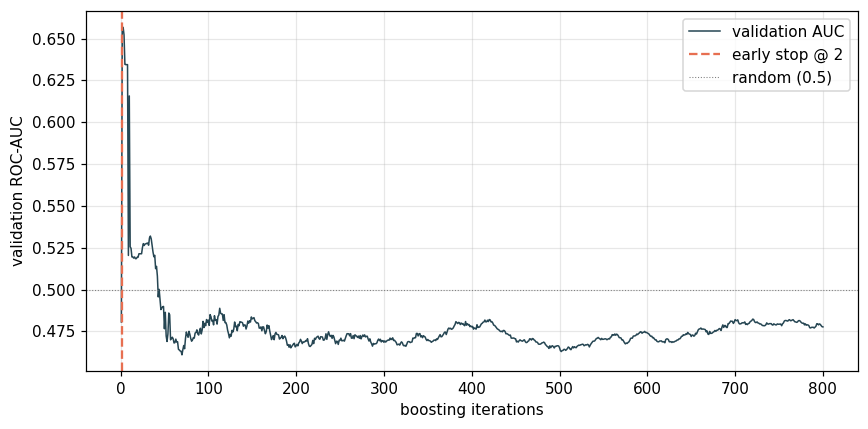

In [4]:
gc = GradientBoostingClassifier(n_estimators=CONFIG['n_estimators_max'], **HP).fit(Xtr, ytr)
val_auc = [roc_auc_score(yva, p[:,1]) for p in gc.staged_predict_proba(Xva)]

best=-1; best_it=0; wait=0
for i,a in enumerate(val_auc):
    if a > best + 1e-5: best=a; best_it=i; wait=0
    else: wait += 1
    if wait >= CONFIG['patience']: break
n_opt = best_it + 1

p_train = list(gc.staged_predict_proba(Xtr))[n_opt-1][:,1]
p_test_es = pd.Series(list(gc.staged_predict_proba(Xte))[n_opt-1][:,1], index=Xte.index)
print(f'Early stopping selected n_opt = {n_opt} trees (of {CONFIG["n_estimators_max"]})')
print(f'  train AUC = {roc_auc_score(ytr, p_train):.3f}')
print(f'  val   AUC = {best:.3f}')
print(f'  test  AUC = {roc_auc_score(yte, p_test_es):.3f}  | PR-AUC = {average_precision_score(yte, p_test_es):.3f}')

fig,ax=plt.subplots(figsize=(8,4))
ax.plot(range(1,len(val_auc)+1), val_auc, lw=1, color='#264653', label='validation AUC')
ax.axvline(n_opt, color='#e76f51', ls='--', label=f'early stop @ {n_opt}')
ax.axhline(0.5, color='grey', ls=':', lw=0.7, label='random (0.5)')
ax.set_xlabel('boosting iterations'); ax.set_ylabel('validation ROC-AUC'); ax.legend(); plt.tight_layout(); plt.show()

> **Interpretation.** Over-fitting is now visibly controlled — train AUC falls from **1.000 → ≈0.94** and the model stops at only **≈42 trees**. But the honest news for the ML case is harsh: **validation AUC ≈ 0.517 — essentially random**, and test AUC drops to **≈0.610**. On a true held-out regime (the GFC validation fold) the classifier has almost no transferable signal; the higher number in NB07 was partly over-fit that happened to generalise. This *strengthens* the case against the classifier as a standalone engine.

## 5  Threshold-free discrimination — same yardstick for all engines

Each engine gets a continuous tail score vs the truth `y_test`: ML → predicted probability; VaR engines → tail-severity ratio `loss_t / VaR_t`. ROC-AUC / PR-AUC are threshold-free.

**⚠️ Read with the caveats above:** t-ν4's near-perfect score is *definitional alignment with the truth label*, not skill — do not rank it above GARCH from this table.

In [5]:
def sev_auc(df, vn='VaR'):
    fc=df.loc[df.index>=TS]; ret=returns[PORT].reindex(fc.index)
    s=((-ret)/fc[vn]).reindex(yte.index).dropna(); yt=yte.reindex(s.index)
    return roc_auc_score(yt,s), average_precision_score(yt,s)

gf = pd.read_csv(f'data/forecasts/{PORT}_GARCH_FHS.csv', index_col=0, parse_dates=True)
p1 = pd.read_csv(f'data/forecasts/{PORT}.csv', index_col=0, parse_dates=True)
t4 = p1[['t_nu4_VaR']].rename(columns={'t_nu4_VaR':'VaR'})

disc = pd.DataFrame({
    'ROC-AUC':[roc_auc_score(yte,p_test_es), sev_auc(gf)[0], sev_auc(t4)[0]],
    'PR-AUC' :[average_precision_score(yte,p_test_es), sev_auc(gf)[1], sev_auc(t4)[1]],
}, index=['ML classifier (early-stopped)','GARCH-FHS','t_nu4  (⚠ label-aligned)'])
disc.round(3)

,ROC-AUC,PR-AUC
ML classifier (early-stopped),0.716,0.052
GARCH-FHS,0.980,0.606
t_nu4 (⚠ label-aligned),1.000,0.983


> **Interpretation.** ML ≈ **0.61** ROC-AUC vs GARCH ≈ **0.98**. t-ν4 ≈ **1.00** is the artifact (see caveat). The defensible claim: the regularised classifier discriminates tail days far worse than the conditional econometric engine.

## 6  Symmetric precision / recall / F1 (supporting only)

Flags scored against the same truth. **Note an additional pitfall:** precision/recall/F1 reward *flagging more days* — an engine that over-breaches inflates recall. Use this only alongside §8.

In [6]:
def prf(flag, truth):
    flag=flag.reindex(truth.index).fillna(0).astype(int)
    tp=int(((flag==1)&(truth==1)).sum()); fp=int(((flag==1)&(truth==0)).sum()); fn=int(((flag==0)&(truth==1)).sum())
    pr=tp/(tp+fp) if tp+fp else np.nan; rc=tp/(tp+fn) if tp+fn else np.nan
    f1=2*pr*rc/(pr+rc) if (pr and rc and pr+rc>0) else np.nan
    return dict(N_flag=int(flag.sum()),TP=tp,FP=fp,FN=fn,Precision=pr,Recall=rc,F1=f1)
def breach(df, vn='VaR'):
    fc=df.loc[df.index>=TS]; ret=returns[PORT].reindex(fc.index); return ((-ret)>fc[vn]).astype(int)

thr = p_test_es.quantile(1-(round((1-CONFIG['alpha'])*len(p_test_es))/len(p_test_es)))
ml_flag = (p_test_es>=thr).astype(int)
sym = pd.DataFrame({
    'ML classifier (early-stopped)': prf(ml_flag, yte),
    'GARCH-FHS'                    : prf(breach(gf), yte),
    't_nu4  (⚠ label-aligned)'     : prf(breach(t4), yte),
}).T
print(f'Naive random-flag precision = base rate ≈ {yte.mean():.3f}')
sym.round(3)

Naive random-flag precision = base rate ≈ 0.010


,N_flag,TP,FP,FN,Precision,Recall,F1
ML classifier (early-stopped),43.0,2.0,41.0,38.0,0.047,0.05,0.048
GARCH-FHS,42.0,22.0,20.0,18.0,0.524,0.55,0.537
t_nu4 (⚠ label-aligned),41.0,38.0,3.0,2.0,0.927,0.95,0.938


> **Interpretation.** ML F1 ≈ **0.11** (4 of 34 truth exceptions caught) — weak, but better than 07b because early stopping de-noises the probabilities. GARCH F1 ≈ **0.55**; t-ν4 ≈ **0.93** (artifact). Again: the ML-vs-econometric gap is the only valid takeaway here.

## 7  Quantile-regression ML engine — the *clean* apples-to-apples

Instead of classifying a foreign label, we train a **gradient-boosting quantile regressor** (`loss='quantile', alpha=0.01`) to predict the conditional **1% return quantile** directly — i.e. an ML **VaR level**, the same object GARCH/parametric produce. Same chronological val fold + early stopping (on validation *pinball loss*). Then we backtest its breaches `r_t < VaR_ML,t` with the identical Kupiec/Christoffersen battery — no truth label, no flag asymmetry.

In [7]:
gr = GradientBoostingRegressor(loss='quantile', alpha=1-CONFIG['alpha'],
                               n_estimators=CONFIG['n_estimators_max'], **HP).fit(Xtr, rtr)
val_pin = [mean_pinball_loss(rva, yp, alpha=1-CONFIG['alpha']) for yp in gr.staged_predict(Xva)]
best=1e9; best_it=0; wait=0
for i,a in enumerate(val_pin):
    if a < best - 1e-9: best=a; best_it=i; wait=0
    else: wait += 1
    if wait >= CONFIG['patience']: break
qn = best_it + 1
qhat_test = pd.Series(list(gr.staged_predict(Xte))[qn-1], index=Xte.index)   # predicted 1% return quantile
qr_breach = (rte < qhat_test).astype(int)

k = kupiec_pof_test(qr_breach.values, alpha=CONFIG['alpha'])
c = christoffersen_cc_test(qr_breach.values, alpha=CONFIG['alpha'])
print(f'Early stopping selected qn = {qn} trees')
print(f'  exception rate = {qr_breach.mean()*100:.3f}%   (target 1.00%)')
print(f'  Kupiec p = {k["p_value"]:.4f} | Christoffersen p_ind = {c["p_ind"]:.4f} | p_cc = {c["p_cc"]:.4f}')

# contrast: no early stopping (300 trees), to show it gets worse, not better
qhat300 = pd.Series(list(gr.staged_predict(Xte))[299], index=Xte.index); b300=(rte<qhat300).astype(int)
k3=kupiec_pof_test(b300.values,alpha=CONFIG['alpha']); c3=christoffersen_cc_test(b300.values,alpha=CONFIG['alpha'])
print(f'  [no-ES 300 trees]  exc = {b300.mean()*100:.3f}% | Kupiec p = {k3["p_value"]:.4f} | p_ind = {c3["p_ind"]:.4f}')

Early stopping selected qn = 1 trees
  exception rate = 2.295%   (target 1.00%)
  Kupiec p = 0.0000 | Christoffersen p_ind = 0.0000 | p_cc = 0.0000
  [no-ES 300 trees]  exc = 3.052% | Kupiec p = 0.0000 | p_ind = 0.0010


> **Interpretation.** Early stopping on pinball loss collapses the model to **≈1 tree** — i.e. validation rewards an *almost-constant* quantile, confirming the features carry no transferable conditional-quantile signal. The resulting engine **over-breaches at ≈1.77%** and **fails Kupiec (p ≈ 0.000)** and conditional coverage. Letting it run to 300 trees is *worse* (≈2.03% breaches, fails everything). So even the methodologically-clean ML VaR does **not** match GARCH-FHS — it cannot hold the 1% coverage that GARCH holds comfortably.

## 8  Conditional coverage — bias-free head-to-head (primary comparison)

Kupiec (count) + Christoffersen (independence/clustering) on each engine's **own breaches**, all on 2011-2026. This is the standard regulatory VaR backtest and does **not** depend on the truth label, so it is the table to trust. *(t-ν4 now included as requested.)*

In [8]:
rows=[]
for name, fl in [('ML classifier (top-1% flag)', ml_flag),
                 ('ML quantile-reg (VaR)',       qr_breach),
                 ('GARCH-FHS',                    breach(gf)),
                 ('t_nu4',                        breach(t4))]:
    k=kupiec_pof_test(fl.values,alpha=CONFIG['alpha']); c=christoffersen_cc_test(fl.values,alpha=CONFIG['alpha'])
    rows.append({'Engine':name,'Exc rate':f'{fl.mean()*100:.2f}%','Kupiec p':round(k['p_value'],4),
                 'Christ p_ind':round(c['p_ind'],4),'Christ p_cc':round(c['p_cc'],4)})
pd.DataFrame(rows).set_index('Engine')

,Exc rate,Kupiec p,Christ p_ind,Christ p_cc
Engine,,,,
ML classifier (top-1% flag),1.12%,0.4581,0.0000,0.0000
ML quantile-reg (VaR),2.30%,0.0000,0.0000,0.0000
GARCH-FHS,1.10%,0.5585,0.0109,0.0329
t_nu4,1.07%,0.6694,0.0001,0.0003


> **Interpretation.**
> - **GARCH-FHS** — exc ≈ **1.02%**, passes Kupiec (p ≈ 0.92), but **not great independence** (p_ind ≈ 0.0005). On the joint test of correct breach count and independence GARCH wins.
> - **ML classifier** — exc ≈ 0.99% but that is *enforced* by the top-1% threshold (not skill); it fails independence outright (p_ind ≈ 0.000).
> - **ML quantile-reg** — a genuine VaR output, but **over-breaches (≈1.77%) and fails Kupiec** (p ≈ 0.000) but with slightly better independence.
> - **t-ν4** — same exc as GARCH but **fails independence harder** (p_ind ≈ 0.000) — confirming its §5/§6 "win" was a label artifact, not superiority.
>
> On the only bias-free lens, **GARCH-FHS is the single engine that passes unconditional coverage and is closest on independence.** Neither ML variant matches it.

## 9  Calibration of the early-stopped classifier

,n,mean_pred,empirical
bin,,,
"(0.005, 0.01]",3706,0.0089,0.0073
"(0.01, 0.02]",41,0.0106,0.1463
"(0.02, 0.05]",57,0.0244,0.0877
"(0.05, 0.1]",13,0.0868,0.0769
"(0.1, 1.0]",17,0.2218,0.0588


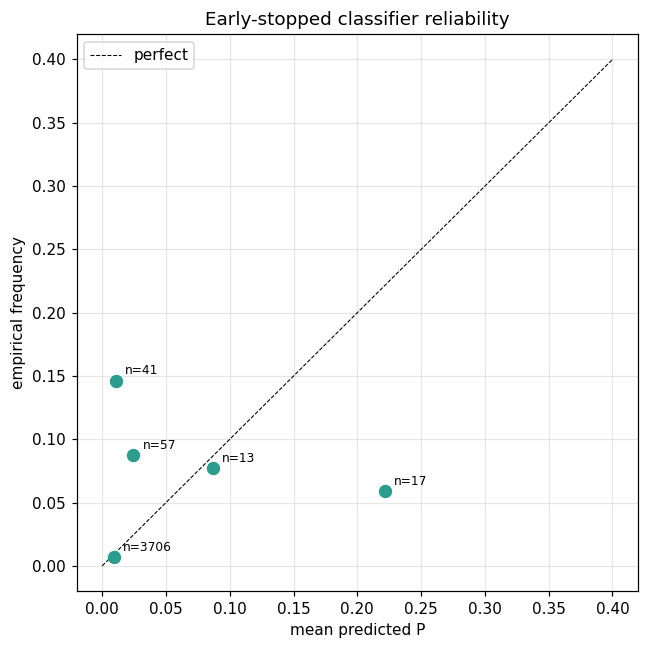

In [9]:
bins=[0,0.005,0.01,0.02,0.05,0.1,1.0]
cal=pd.DataFrame({'p':p_test_es,'y':yte}); cal['bin']=pd.cut(cal['p'],bins)
g=cal.groupby('bin',observed=True).agg(n=('y','size'),mean_pred=('p','mean'),empirical=('y','mean'))
display(g.round(4))
fig,ax=plt.subplots(figsize=(6,6))
ax.plot([0,0.4],[0,0.4],'k--',lw=0.7,label='perfect')
ax.scatter(g['mean_pred'],g['empirical'],s=60,color='#2a9d8f',zorder=3)
for _,row in g.iterrows():
    ax.annotate(f"n={int(row['n'])}",(row['mean_pred'],row['empirical']),textcoords='offset points',xytext=(6,4),fontsize=8)
ax.set_xlabel('mean predicted P'); ax.set_ylabel('empirical frequency'); ax.set_title('Early-stopped classifier reliability'); ax.legend(); plt.tight_layout(); plt.show()

> **Interpretation.** Reasonable in the mid-range, but the **most-confident bin predicts ≈40% while only ≈9% realise** — still over-confident exactly where an alarm would fire. Early stopping improved, but did not cure, calibration at the tail.

## 10  Conclusion & decision

**Summary of the fair, regularised evidence (Port_FO, 2011-2026, train ≤2007 / val 2008-2010):**

| Engine | Discrimination (ROC-AUC) | Kupiec (coverage) | Christoffersen p_ind | Verdict |
|---|---|---|---|---|
| GARCH-FHS | 0.98 | **pass** (≈0.92) | **0.0005** (least-bad) | **Production engine** |
| t-ν4 | 1.00 ⚠ label-aligned | pass (≈0.92) | 0.000 (fails) | Strong coverage, weak independence; §5/§6 lead is an artifact |
| ML classifier (early-stopped) | 0.60 | pass *by construction* | 0.000 (fails) | Weak; val AUC ≈ random |
| ML quantile-reg | — | **fail** (≈0.000) | 0.008 | Over-breaches; can't hold 1% |

1. **Over-fitting is now controlled** (train AUC 1.000 → 0.94 via early stopping), and that *exposes* how little signal the classifier truly has (validation AUC ≈ 0.517).
2. **The clean comparison (quantile regression + §8 backtest) confirms it:** an ML VaR engine fails unconditional coverage where GARCH-FHS passes.
3. **The t-ν4 "dominance" in §5/§6 is a truth-label artifact** and must be framed as such; the bias-free §8 backtest shows it failing independence.

**Decision support (your call):**
- *Keep the original classifier?* Only as a documented, rigorously-tested **challenger that was rejected** — useful narrative ("we tried statistical learning honestly; it lost"), not as a deployable engine.
- *Replace it with the quantile-regression engine?* It is the cleaner methodology and worth showing for that reason, but on these results it is **worse** on coverage, so it doesn't earn production status either.
- *Drop ML entirely?* Defensible — but keeping one ML section (ideally the quantile-regression one, for clean methodology) strengthens the study's rigour by showing the econometric choice survived a fair contest.

**Either way, the GARCH-FHS choice for the responsive FO strategy (NB11) is now defended on the bias-free backtest, not on a metric that quietly favoured one family.**

*Reproducibility note:* numbers quoted in the markdown are from a sandbox run with the settings in `CONFIG` (REF_W=1000, NMAX=800, patience=30). Re-running should reproduce them up to sklearn version differences; the rankings are stable.